IMPORT LIBRARIES

In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import pickle

from google.colab import files

import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries have been imported successfully!")


✅ All libraries have been imported successfully!


DATASET UNDERSTANDING


In [ ]:
# ============================================================
# Load the dataset (run this if 'df' is not defined)
# ============================================================
from google.colab import files
import pandas as pd

uploaded = files.upload()   # Choose your Merged_Energy_Weather.csv file

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(f"✅ '{filename}' loaded into df successfully! Shape: {df.shape}")

Saving energy_weather.csv to energy_weather.csv
✅ 'energy_weather.csv' loaded into df successfully! Shape: (121273, 10)


In [ ]:
# ============================================================
# Weather-Based Energy Consumption Prediction
# Step 3: Dataset Understanding
# ============================================================

# ----------------------------
# 1. First 5 rows
# ----------------------------
print("🔹 First 5 rows of the dataset:")
display(df.head())

# ----------------------------
# 2. Last 5 rows
# ----------------------------
print("\n🔹 Last 5 rows of the dataset:")
display(df.tail())

# ----------------------------
# 3. Dataset shape
# ----------------------------
print(f"\n🔹 Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")

# ----------------------------
# 4. Column names
# ----------------------------
print("\n🔹 Column names:")
print(df.columns.tolist())

# ----------------------------
# 5. Data types
# ----------------------------
print("\n🔹 Data types of each column:")
print(df.dtypes)

# ----------------------------
# 6. Missing values
# ----------------------------
print("\n🔹 Missing values per column:")
print(df.isnull().sum())

# ----------------------------
# 7. Duplicate rows
# ----------------------------
duplicate_count = df.duplicated().sum()
print(f"\n🔹 Number of duplicate rows: {duplicate_count}")

# ----------------------------
# 8. Summary statistics
# ----------------------------
print("\n🔹 Summary statistics (numeric columns):")
display(df.describe())

print("\n🔹 Summary statistics (categorical/text columns):")
display(df.describe(include='object'))

# ----------------------------
# 9. Dataset information using info()
# ----------------------------
print("\n🔹 Dataset info:")
df.info()

🔹 First 5 rows of the dataset:


,Datetime,AEP_MW,Temperature,Humidity,Wind Speed,Pressure,Dew Point,Cloud Cover,Visibility,Weather Condition
0,31-12-2004 01:00,13478,-6.0,100.0,4.7,1007.1,-6.1,80.8,3.7,Rainy
1,31-12-2004 02:00,12865,-7.7,95.4,15.3,1010.0,-8.3,53.9,4.4,Cloudy
2,31-12-2004 03:00,12577,-6.3,83.3,39.7,1006.9,-8.7,53.3,4.7,Cloudy
3,31-12-2004 04:00,12517,-4.4,74.3,16.5,1003.2,-8.3,34.0,8.1,Sunny
4,31-12-2004 05:00,12670,-7.4,95.4,10.3,1014.2,-8.0,41.4,6.7,Cloudy



🔹 Last 5 rows of the dataset:


,Datetime,AEP_MW,Temperature,Humidity,Wind Speed,Pressure,Dew Point,Cloud Cover,Visibility,Weather Condition
121268,01-01-2018 20:00,21089,-2.2,70.3,7.7,1002.1,-6.9,39.8,6.7,Sunny
121269,01-01-2018 21:00,20999,0.6,64.1,16.0,1003.6,-5.4,43.7,6.5,Cloudy
121270,01-01-2018 22:00,20820,-8.1,62.7,5.8,1001.3,-13.9,25.2,7.8,Sunny
121271,01-01-2018 23:00,20415,-0.3,100.0,17.3,1003.4,-0.4,25.7,8.8,Sunny
121272,02-01-2018 00:00,19993,-5.2,73.9,2.9,1000.2,-9.1,33.9,7.6,Sunny



🔹 Dataset shape: 121273 rows and 10 columns

🔹 Column names:
['Datetime', 'AEP_MW', 'Temperature', 'Humidity', 'Wind Speed', 'Pressure', 'Dew Point', 'Cloud Cover', 'Visibility', 'Weather Condition']

🔹 Data types of each column:
Datetime              object
AEP_MW                 int64
Temperature          float64
Humidity             float64
Wind Speed           float64
Pressure             float64
Dew Point            float64
Cloud Cover          float64
Visibility           float64
Weather Condition     object
dtype: object

🔹 Missing values per column:
Datetime             0
AEP_MW               0
Temperature          0
Humidity             0
Wind Speed           0
Pressure             0
Dew Point            0
Cloud Cover          0
Visibility           0
Weather Condition    0
dtype: int64

🔹 Number of duplicate rows: 0

🔹 Summary statistics (numeric columns):


,AEP_MW,Temperature,Humidity,Wind Speed,Pressure,Dew Point,Cloud Cover,Visibility
count,121273.000000,121273.000000,121273.000000,121273.000000,121273.000000,121273.000000,121273.000000,121273.000000
mean,15499.513717,11.889242,69.978180,12.023812,1013.017941,6.273261,42.222134,7.223432
std,2591.399065,11.367319,13.252144,8.536221,7.541309,10.537177,20.905851,2.152899
min,9581.000000,-14.000000,20.200000,0.000000,983.900000,-17.800000,0.000000,0.200000
25%,13630.000000,2.100000,59.900000,5.800000,1007.500000,-3.400000,27.500000,5.700000
50%,15310.000000,11.800000,70.000000,10.000000,1013.100000,6.100000,42.100000,7.200000
75%,17200.000000,21.700000,80.000000,16.000000,1018.600000,16.000000,56.400000,8.700000
max,25695.000000,38.000000,100.000000,80.000000,1039.700000,31.300000,100.000000,15.000000



🔹 Summary statistics (categorical/text columns):


,Datetime,Weather Condition
count,121273,121273
unique,121269,3
top,01-11-2015 02:00,Cloudy
freq,2,60838



🔹 Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Datetime           121273 non-null  object 
 1   AEP_MW             121273 non-null  int64  
 2   Temperature        121273 non-null  float64
 3   Humidity           121273 non-null  float64
 4   Wind Speed         121273 non-null  float64
 5   Pressure           121273 non-null  float64
 6   Dew Point          121273 non-null  float64
 7   Cloud Cover        121273 non-null  float64
 8   Visibility         121273 non-null  float64
 9   Weather Condition  121273 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 9.3+ MB


DATA PRE-PROCESSING

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Data Preprocessing Phase
# =========================================================

import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. Create a copy of the original dataset
# ---------------------------------------------------------
data = df.copy()
shape_before = data.shape

# ---------------------------------------------------------
# 2. Check and handle missing values
# ---------------------------------------------------------
print("Missing values before handling:\n", data.isnull().sum())

# Fill numeric columns with median, categorical columns with mode
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if data[col].dtype in ['int64', 'float64']:
            data[col] = data[col].fillna(data[col].median())
        else:
            data[col] = data[col].fillna(data[col].mode()[0])

print("\nMissing values after handling:\n", data.isnull().sum())

# ---------------------------------------------------------
# 3. Check and remove duplicate rows
# ---------------------------------------------------------
print("\nDuplicate rows found:", data.duplicated().sum())
data = data.drop_duplicates()
print("Duplicate rows after removal:", data.duplicated().sum())

# ---------------------------------------------------------
# 4. Verify and correct data types
# ---------------------------------------------------------
print("\nData types before correction:\n", data.dtypes)

# ---------------------------------------------------------
# 5. Convert Datetime column to datetime format (if present)
# ---------------------------------------------------------
if 'Datetime' in data.columns:
    data['Datetime'] = pd.to_datetime(data['Datetime'], dayfirst=True, errors='coerce')

    # ---------------------------------------------------------
    # 6. Extract Year, Month, Day, Hour, Weekday
    # ---------------------------------------------------------
    data['Year'] = data['Datetime'].dt.year
    data['Month'] = data['Datetime'].dt.month
    data['Day'] = data['Datetime'].dt.day
    data['Hour'] = data['Datetime'].dt.hour
    data['Weekday'] = data['Datetime'].dt.weekday

    # ---------------------------------------------------------
    # 7. Drop the original Datetime column
    # ---------------------------------------------------------
    data = data.drop(columns=['Datetime'])

print("\nData types after correction:\n", data.dtypes)

# ---------------------------------------------------------
# 8. Identify and One-Hot Encode categorical columns
# ---------------------------------------------------------
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
print("\nCategorical columns found:", categorical_cols)

if categorical_cols:
    data = pd.get_dummies(data, columns=categorical_cols, drop_first=True)

# ---------------------------------------------------------
# 9. Detect outliers using IQR method
# ---------------------------------------------------------
numerical_cols = data.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("\nOutlier count per numerical column (IQR method):")
for col in numerical_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    print(f"{col}: {outliers.shape[0]} outliers")

# ---------------------------------------------------------
# 10. Apply feature scaling only if required
# ---------------------------------------------------------
# Scaling is useful for distance-based models (KNN, SVM, etc.)
# Skip if only tree-based models (Random Forest, XGBoost) will be used.
apply_scaling = True  # Set to False to skip scaling

if apply_scaling:
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    cols_to_scale = [col for col in numerical_cols if col not in
                      ['Year', 'Month', 'Day', 'Hour', 'Weekday']]
    data[cols_to_scale] = scaler.fit_transform(data[cols_to_scale])
    print("\nFeature scaling applied on:", cols_to_scale)

# ---------------------------------------------------------
# 11. Final Checks and Display
# ---------------------------------------------------------
shape_after = data.shape

print("\nFirst 5 rows of preprocessed dataset:")
print(data.head())

print("\nDataset shape before preprocessing:", shape_before)
print("Dataset shape after preprocessing:", shape_after)

print("\nUpdated data types:\n", data.dtypes)

print("\nFinal column names:\n", data.columns.tolist())

Missing values before handling:
 Datetime             0
AEP_MW               0
Temperature          0
Humidity             0
Wind Speed           0
Pressure             0
Dew Point            0
Cloud Cover          0
Visibility           0
Weather Condition    0
dtype: int64

Missing values after handling:
 Datetime             0
AEP_MW               0
Temperature          0
Humidity             0
Wind Speed           0
Pressure             0
Dew Point            0
Cloud Cover          0
Visibility           0
Weather Condition    0
dtype: int64

Duplicate rows found: 0
Duplicate rows after removal: 0

Data types before correction:
 Datetime              object
AEP_MW                 int64
Temperature          float64
Humidity             float64
Wind Speed           float64
Pressure             float64
Dew Point            float64
Cloud Cover          float64
Visibility           float64
Weather Condition     object
dtype: object

Data types after correction:
 AEP_MW                 i

FEATUREING ENGINEERING

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 5: Feature Engineering
# =========================================================

import pandas as pd

# Work on a copy to keep original data safe
data = df.copy()

# ---------------------------------------------------------
# 1. Extract date/time features (if Datetime column exists)
# ---------------------------------------------------------
if 'Datetime' in data.columns:
    data['Datetime'] = pd.to_datetime(data['Datetime'], dayfirst=True, errors='coerce')

    data['Year'] = data['Datetime'].dt.year
    data['Month'] = data['Datetime'].dt.month
    data['Day'] = data['Datetime'].dt.day
    data['Hour'] = data['Datetime'].dt.hour
    data['Weekday'] = data['Datetime'].dt.weekday

    # Drop the original Datetime column
    data = data.drop(columns=['Datetime'])

    print("Datetime features created: Year, Month, Day, Hour, Weekday")
else:
    print("No Datetime column found, skipping date/time feature extraction.")

# ---------------------------------------------------------
# 2. One-Hot Encode categorical columns
# ---------------------------------------------------------
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
print("\nCategorical columns found:", categorical_cols)

if categorical_cols:
    data = pd.get_dummies(data, columns=categorical_cols, drop_first=True)
    print("One-Hot Encoding applied on:", categorical_cols)

# ---------------------------------------------------------
# 3. Display updated dataset
# ---------------------------------------------------------
print("\nDataset shape after feature engineering:", data.shape)

print("\nFirst 5 rows of updated dataset:")
print(data.head())

print("\nUpdated data types:\n", data.dtypes)

print("\nFinal column names:\n", data.columns.tolist())

Datetime features created: Year, Month, Day, Hour, Weekday

Categorical columns found: ['Weather Condition']
One-Hot Encoding applied on: ['Weather Condition']

Dataset shape after feature engineering: (121273, 15)

First 5 rows of updated dataset:
   AEP_MW  Temperature  Humidity  Wind Speed  Pressure  Dew Point  \
0   13478         -6.0     100.0         4.7    1007.1       -6.1   
1   12865         -7.7      95.4        15.3    1010.0       -8.3   
2   12577         -6.3      83.3        39.7    1006.9       -8.7   
3   12517         -4.4      74.3        16.5    1003.2       -8.3   
4   12670         -7.4      95.4        10.3    1014.2       -8.0   

   Cloud Cover  Visibility  Year  Month  Day  Hour  Weekday  \
0         80.8         3.7  2004     12   31     1        4   
1         53.9         4.4  2004     12   31     2        4   
2         53.3         4.7  2004     12   31     3        4   
3         34.0         8.1  2004     12   31     4        4   
4         41.4       

EXPLORATORY DATA ANALYSIS (EDA)

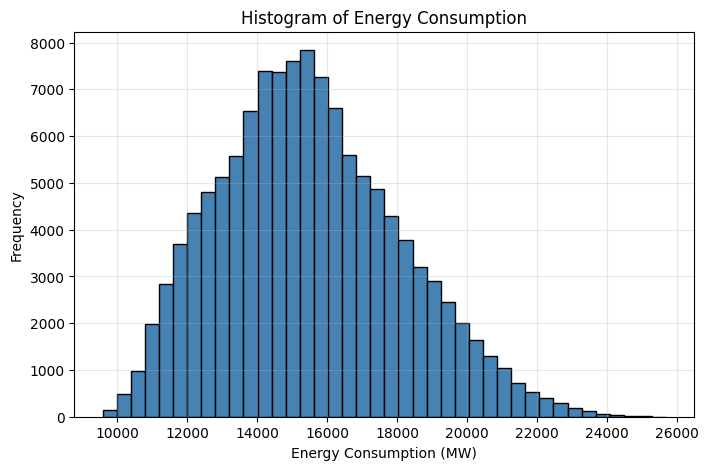

Most energy consumption values cluster around a central range, showing a roughly normal-ish distribution with some spread.


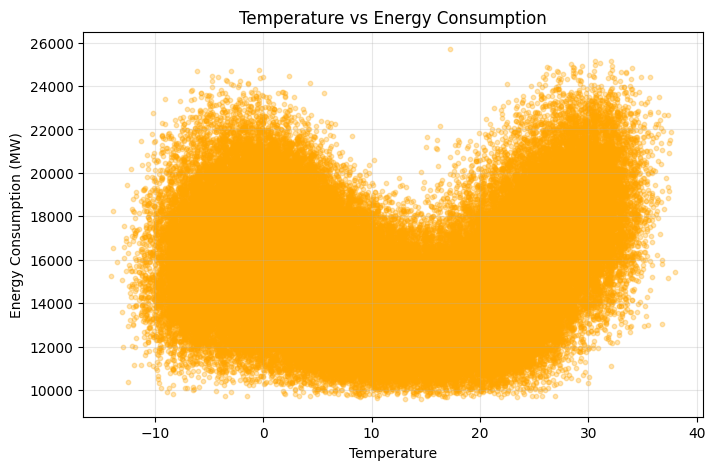

Energy consumption tends to rise at both very low and very high temperatures, suggesting heating and cooling demand effects.


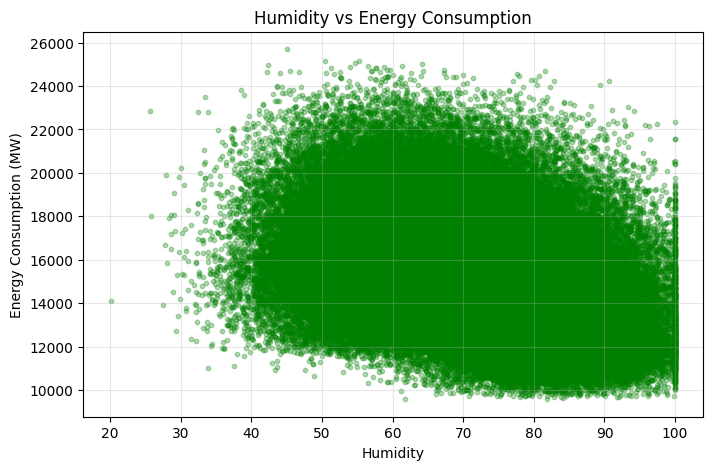

Humidity shows a weaker and more scattered relationship with energy consumption compared to temperature.


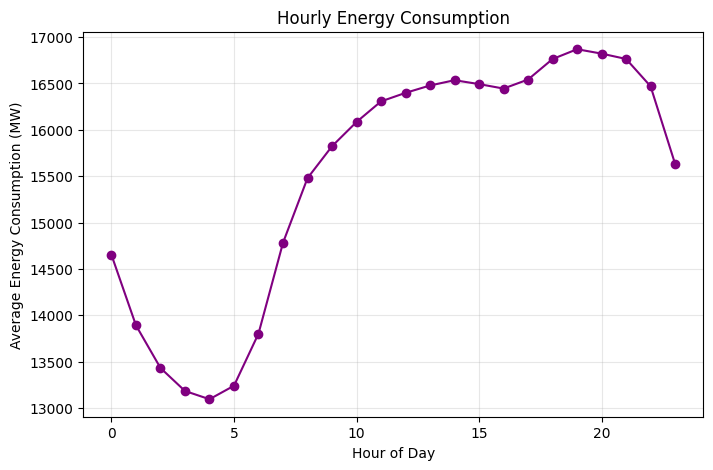

Energy consumption follows a daily cycle, typically peaking during morning and evening active hours.


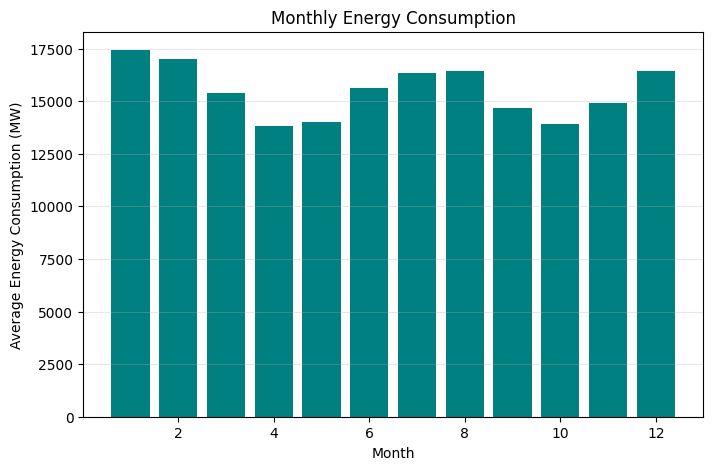

Average energy consumption varies across months, likely reflecting seasonal heating and cooling needs.


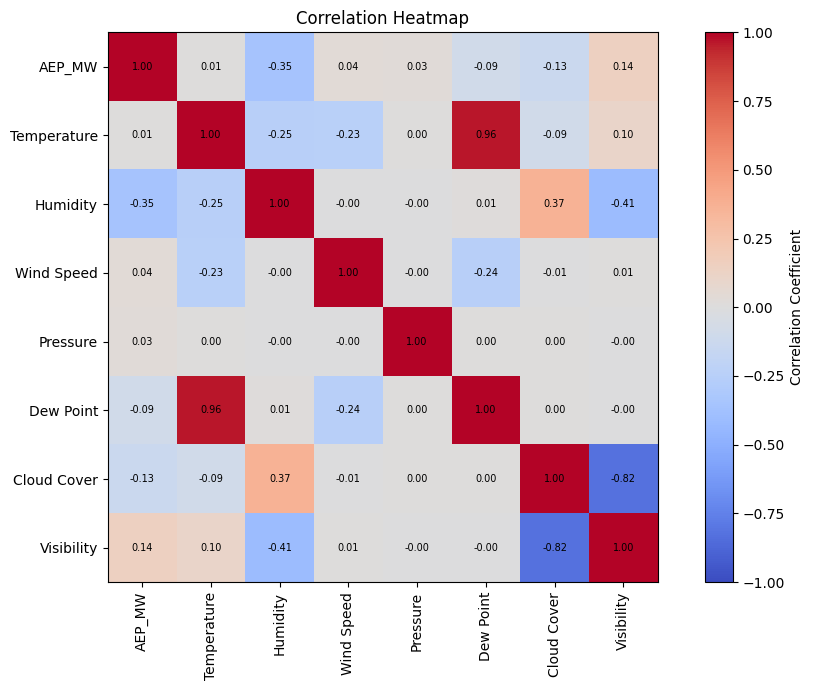

The heatmap highlights which weather variables are most strongly correlated with energy consumption.


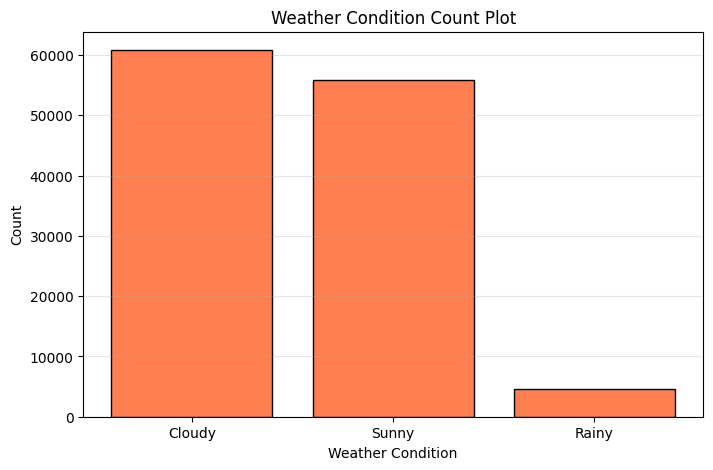

Some weather conditions occur far more frequently than others, showing an imbalance in the dataset.


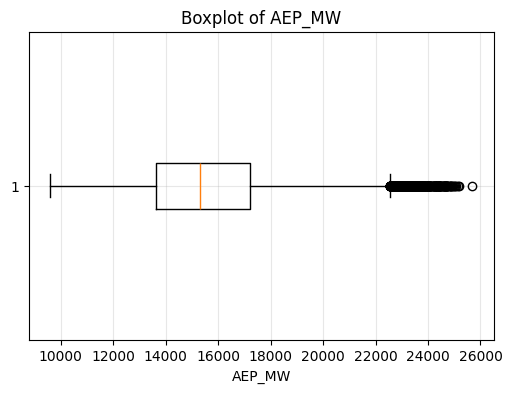

The boxplot of AEP_MW reveals its spread and highlights any potential outliers.


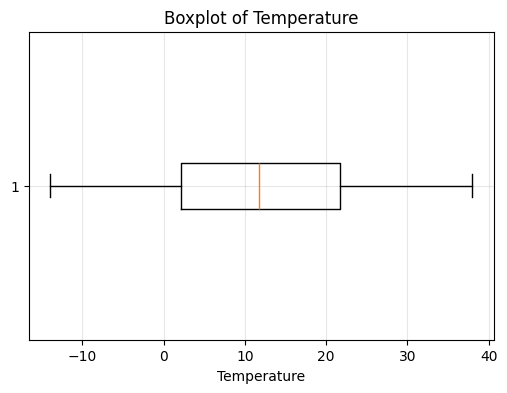

The boxplot of Temperature reveals its spread and highlights any potential outliers.


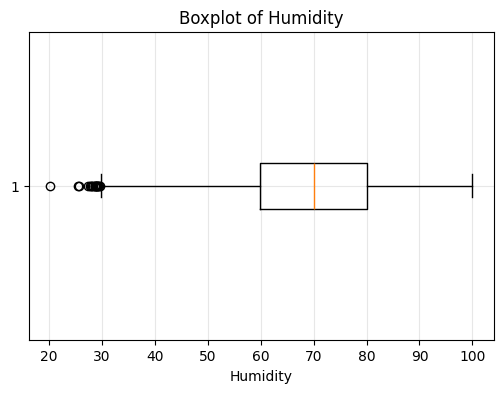

The boxplot of Humidity reveals its spread and highlights any potential outliers.


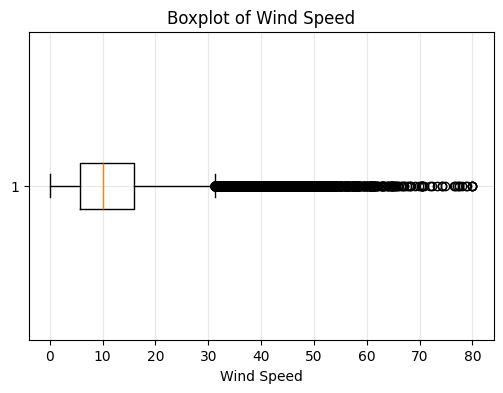

The boxplot of Wind Speed reveals its spread and highlights any potential outliers.


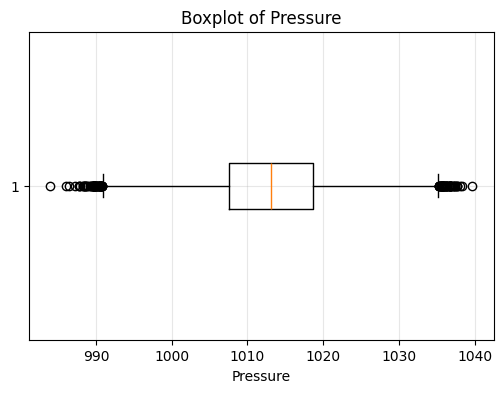

The boxplot of Pressure reveals its spread and highlights any potential outliers.


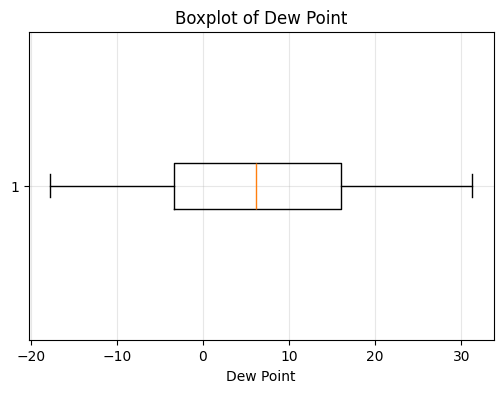

The boxplot of Dew Point reveals its spread and highlights any potential outliers.


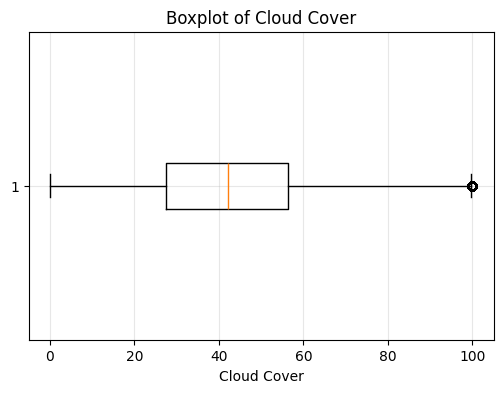

The boxplot of Cloud Cover reveals its spread and highlights any potential outliers.


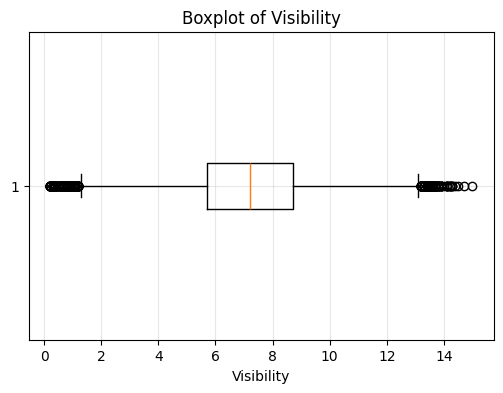

The boxplot of Visibility reveals its spread and highlights any potential outliers.


In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 6: Exploratory Data Analysis (EDA)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Work on a copy to keep original data safe
eda_data = df.copy()

# ---------------------------------------------------------
# Prepare helper columns (Hour, Month) if Datetime exists
# ---------------------------------------------------------
if 'Datetime' in eda_data.columns:
    eda_data['Datetime'] = pd.to_datetime(eda_data['Datetime'], dayfirst=True, errors='coerce')
    eda_data['Hour'] = eda_data['Datetime'].dt.hour
    eda_data['Month'] = eda_data['Datetime'].dt.month

# Target column (energy consumption)
target_col = 'AEP_MW'

# ---------------------------------------------------------
# 1. Histogram of Energy Consumption
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.hist(eda_data[target_col], bins=40, color='steelblue', edgecolor='black')
plt.title('Histogram of Energy Consumption')
plt.xlabel('Energy Consumption (MW)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()
print("Most energy consumption values cluster around a central range, showing a roughly normal-ish distribution with some spread.")

# ---------------------------------------------------------
# 2. Temperature vs Energy Consumption
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(eda_data['Temperature'], eda_data[target_col], alpha=0.3, color='orange', s=10)
plt.title('Temperature vs Energy Consumption')
plt.xlabel('Temperature')
plt.ylabel('Energy Consumption (MW)')
plt.grid(True, alpha=0.3)
plt.show()
print("Energy consumption tends to rise at both very low and very high temperatures, suggesting heating and cooling demand effects.")

# ---------------------------------------------------------
# 3. Humidity vs Energy Consumption
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(eda_data['Humidity'], eda_data[target_col], alpha=0.3, color='green', s=10)
plt.title('Humidity vs Energy Consumption')
plt.xlabel('Humidity')
plt.ylabel('Energy Consumption (MW)')
plt.grid(True, alpha=0.3)
plt.show()
print("Humidity shows a weaker and more scattered relationship with energy consumption compared to temperature.")

# ---------------------------------------------------------
# 4. Hourly Energy Consumption
# ---------------------------------------------------------
hourly_avg = eda_data.groupby('Hour')[target_col].mean()

plt.figure(figsize=(8, 5))
plt.plot(hourly_avg.index, hourly_avg.values, marker='o', color='purple')
plt.title('Hourly Energy Consumption')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.grid(True, alpha=0.3)
plt.show()
print("Energy consumption follows a daily cycle, typically peaking during morning and evening active hours.")

# ---------------------------------------------------------
# 5. Monthly Energy Consumption
# ---------------------------------------------------------
monthly_avg = eda_data.groupby('Month')[target_col].mean()

plt.figure(figsize=(8, 5))
plt.bar(monthly_avg.index, monthly_avg.values, color='teal')
plt.title('Monthly Energy Consumption')
plt.xlabel('Month')
plt.ylabel('Average Energy Consumption (MW)')
plt.grid(True, alpha=0.3, axis='y')
plt.show()
print("Average energy consumption varies across months, likely reflecting seasonal heating and cooling needs.")

# ---------------------------------------------------------
# 6. Correlation Heatmap
# ---------------------------------------------------------
numeric_cols = eda_data.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = eda_data[numeric_cols].corr()

plt.figure(figsize=(10, 7))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation Coefficient')
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Correlation Heatmap')
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
plt.tight_layout()
plt.show()
print("The heatmap highlights which weather variables are most strongly correlated with energy consumption.")

# ---------------------------------------------------------
# 7. Weather Condition Count Plot
# ---------------------------------------------------------
if 'Weather Condition' in eda_data.columns:
    condition_counts = eda_data['Weather Condition'].value_counts()

    plt.figure(figsize=(8, 5))
    plt.bar(condition_counts.index, condition_counts.values, color='coral', edgecolor='black')
    plt.title('Weather Condition Count Plot')
    plt.xlabel('Weather Condition')
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3, axis='y')
    plt.show()
    print("Some weather conditions occur far more frequently than others, showing an imbalance in the dataset.")

# ---------------------------------------------------------
# 8. Boxplots for Numerical Columns
# ---------------------------------------------------------
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    plt.boxplot(eda_data[col].dropna(), vert=False)
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.grid(True, alpha=0.3)
    plt.show()
    print(f"The boxplot of {col} reveals its spread and highlights any potential outliers.")

FEATURE SELECTION

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 7: Feature Selection
# =========================================================

import pandas as pd

# Use the preprocessed & feature-engineered dataset from previous steps
model_data = data.copy()

# ---------------------------------------------------------
# 1. Select target variable (y)
# ---------------------------------------------------------
target_col = 'AEP_MW'
y = model_data[target_col]

# ---------------------------------------------------------
# 2. Select input features (X)
# ---------------------------------------------------------
X = model_data.drop(columns=[target_col])

# ---------------------------------------------------------
# 3. Display selected columns
# ---------------------------------------------------------
print("Target variable (y):", target_col)
print("\nInput feature columns (X):")
print(X.columns.tolist())

# ---------------------------------------------------------
# 4. Print shapes of X and y
# ---------------------------------------------------------
print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Target variable (y): AEP_MW

Input feature columns (X):
['Temperature', 'Humidity', 'Wind Speed', 'Pressure', 'Dew Point', 'Cloud Cover', 'Visibility', 'Year', 'Month', 'Day', 'Hour', 'Weekday', 'Weather Condition_Rainy', 'Weather Condition_Sunny']

Shape of X: (121273, 14)
Shape of y: (121273,)


TRAIN - TEST SPLIT

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 8: Train-Test Split
# =========================================================

from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# Split data into 80% training and 20% testing sets
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------------------------------------------------
# Print shapes of the resulting splits
# ---------------------------------------------------------
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (97018, 14)
Shape of X_test: (24255, 14)
Shape of y_train: (97018,)
Shape of y_test: (24255,)


MODEL TRAINING

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 9: Machine Learning Model Training
# =========================================================

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Linear Regression
# ---------------------------------------------------------
lr_model = LinearRegression()          # initialize model
lr_model.fit(X_train, y_train)         # train model
y_pred_lr = lr_model.predict(X_test)   # predict on test data

# ---------------------------------------------------------
# 2. Decision Tree Regressor
# ---------------------------------------------------------
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# ---------------------------------------------------------
# 3. Random Forest Regressor
# ---------------------------------------------------------
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# ---------------------------------------------------------
# 4. Gradient Boosting Regressor
# ---------------------------------------------------------
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

# ---------------------------------------------------------
# Confirm predictions stored
# ---------------------------------------------------------
print("Models trained and predictions generated:")
print("Linear Regression predictions:", y_pred_lr.shape)
print("Decision Tree predictions:", y_pred_dt.shape)
print("Random Forest predictions:", y_pred_rf.shape)
print("Gradient Boosting predictions:", y_pred_gb.shape)

# ---------------------------------------------------------
# 5. Calculate accuracy (R2 Score) for each model
# ---------------------------------------------------------
models_preds = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = []
for name, y_pred in models_preds.items():
    r2 = r2_score(y_test, y_pred)                          # accuracy (R2 score)
    mae = mean_absolute_error(y_test, y_pred)               # avg absolute error
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))      # root mean squared error
    results.append([name, r2, mae, rmse])

results_df = pd.DataFrame(results, columns=["Model", "R2 Score (Accuracy)", "MAE", "RMSE"])
results_df = results_df.sort_values(by="R2 Score (Accuracy)", ascending=False).reset_index(drop=True)

print("\nModel Accuracy Comparison:")
print(results_df)

Models trained and predictions generated:
Linear Regression predictions: (24255,)
Decision Tree predictions: (24255,)
Random Forest predictions: (24255,)
Gradient Boosting predictions: (24255,)

Model Accuracy Comparison:
               Model  R2 Score (Accuracy)          MAE         RMSE
0      Random Forest             0.861773   718.255689   962.847338
1      Decision Tree             0.736970   914.904515  1328.198339
2  Gradient Boosting             0.722095  1051.225971  1365.240078
3  Linear Regression             0.318233  1722.814952  2138.349048


MODEL EVALUATION


In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Step 10: Model Evaluation
# =========================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------------------------------------
# What each metric means:
# MAE  -> Mean Absolute Error: average absolute difference between actual and predicted values (lower is better)
# MSE  -> Mean Squared Error: average squared difference between actual and predicted values (lower is better)
# RMSE -> Root Mean Squared Error: square root of MSE, in the same unit as the target (lower is better)
# R2   -> R-Squared Score: how much variance in the target is explained by the model (closer to 1 is better)
# ---------------------------------------------------------

# ---------------------------------------------------------
# 1. Collect predictions from all trained models
# ---------------------------------------------------------
models_preds = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

# ---------------------------------------------------------
# 2. Calculate MAE, MSE, RMSE, R2 for each model
# ---------------------------------------------------------
evaluation_results = []

for model_name, y_pred in models_preds.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    evaluation_results.append([model_name, mae, mse, rmse, r2])

# ---------------------------------------------------------
# 3. Build comparison table
# ---------------------------------------------------------
comparison_df = pd.DataFrame(
    evaluation_results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

comparison_df = comparison_df.sort_values(by="R2 Score", ascending=False).reset_index(drop=True)

print("Model Evaluation Comparison Table:\n")
print(comparison_df)

# ---------------------------------------------------------
# 4. Highlight the best-performing model
# ---------------------------------------------------------
best_model_name = comparison_df.iloc[0]["Model"]
best_r2 = comparison_df.iloc[0]["R2 Score"]
best_rmse = comparison_df.iloc[0]["RMSE"]

print(f"\nBest Performing Model: {best_model_name}")
print(f"R2 Score: {best_r2:.4f}")
print(f"RMSE: {best_rmse:.4f}")

Model Evaluation Comparison Table:

               Model          MAE           MSE         RMSE  R2 Score
0      Random Forest   718.255689  9.270750e+05   962.847338  0.861773
1      Decision Tree   914.904515  1.764111e+06  1328.198339  0.736970
2  Gradient Boosting  1051.225971  1.863880e+06  1365.240078  0.722095
3  Linear Regression  1722.814952  4.572537e+06  2138.349048  0.318233

Best Performing Model: Random Forest
R2 Score: 0.8618
RMSE: 962.8473


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Convert energy consumption into Low, Medium, High categories
# Shared thresholds are based on the actual training data
low_threshold = np.percentile(y_train, 33.33)
high_threshold = np.percentile(y_train, 66.67)

def categorize_energy(values):
    values = np.asarray(values)
    return np.where(
        values <= low_threshold, "Low",
        np.where(values <= high_threshold, "Medium", "High")
    )

# Actual categories
y_actual = categorize_energy(y_test)

# Model predictions
models = {
    "Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = []

for name, predictions in models.items():

    # Classification metrics using consumption categories
    y_pred_category = categorize_energy(predictions)

    accuracy = accuracy_score(y_actual, y_pred_category)
    precision = precision_score(
        y_actual, y_pred_category,
        average="weighted", zero_division=0
    )
    recall = recall_score(
        y_actual, y_pred_category,
        average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_actual, y_pred_category,
        average="weighted", zero_division=0
    )

    # Regression metrics using original MW values
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model / Approach": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2),
        "MAE (MW)": round(mae, 2),
        "RMSE (MW)": round(rmse, 2),
        "R²": round(r2, 4)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R²", ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
print(results_df.to_string(index=False))


MODEL PERFORMANCE COMPARISON
 Model / Approach  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  MAE (MW)  RMSE (MW)     R²
    Random Forest         80.71          81.12       80.71         80.83    718.26     962.85 0.8618
    Decision Tree         76.29          76.27       76.29         76.28    914.90    1328.20 0.7370
Gradient Boosting         71.88          73.24       71.88         72.28   1051.23    1365.24 0.7221
Linear Regression         50.44          55.78       50.44         51.38   1722.81    2138.35 0.3182


FEATURE IMPORTANCE


Feature Importance Ranking (Most to Least Important):

                    Feature  Importance
0                      Hour    0.301903
1               Temperature    0.164361
2                      Year    0.107688
3                   Weekday    0.098472
4                 Dew Point    0.086441
5                       Day    0.078789
6                     Month    0.070811
7                  Pressure    0.025477
8                Wind Speed    0.018175
9                  Humidity    0.016727
10              Cloud Cover    0.015347
11               Visibility    0.014561
12  Weather Condition_Sunny    0.000789
13  Weather Condition_Rainy    0.000460


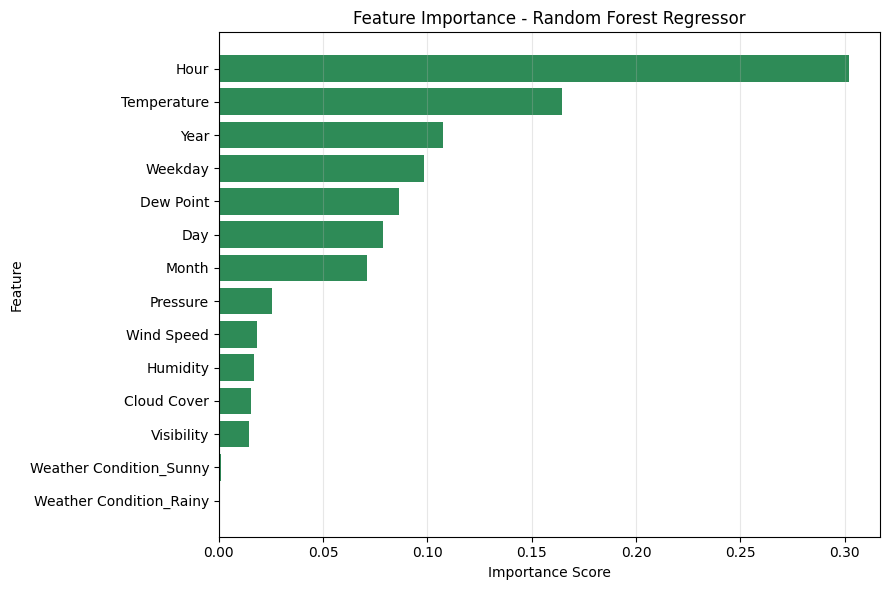


Explanation: This graph shows how much each feature contributes to the Random Forest model's predictions. Features at the top (longer bars) have a stronger influence on predicted energy consumption, while features at the bottom contribute very little. Here, 'Hour' is the most influential feature, meaning changes in it affect the model's output the most.


In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Feature Importance using Random Forest Regressor
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Get feature importance values from trained Random Forest model
# ---------------------------------------------------------
importances = rf_model.feature_importances_
feature_names = X.columns

# ---------------------------------------------------------
# 2. Rank features from most important to least important
# ---------------------------------------------------------
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(by="Importance", ascending=False).reset_index(drop=True)

print("Feature Importance Ranking (Most to Least Important):\n")
print(importance_df)

# ---------------------------------------------------------
# 3. Plot feature importance
# ---------------------------------------------------------
plt.figure(figsize=(9, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="seagreen")
plt.gca().invert_yaxis()  # highest importance on top
plt.title("Feature Importance - Random Forest Regressor")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. Explain what the graph means
# ---------------------------------------------------------
top_feature = importance_df.iloc[0]["Feature"]
print(f"\nExplanation: This graph shows how much each feature contributes to the Random "
      f"Forest model's predictions. Features at the top (longer bars) have a stronger "
      f"influence on predicted energy consumption, while features at the bottom "
      f"contribute very little. Here, '{top_feature}' is the most influential feature, "
      f"meaning changes in it affect the model's output the most.")

PICKLE SAVING

In [ ]:
# =========================================================
# Weather-Based Energy Consumption Prediction
# Save the Best Model (Random Forest) using Pickle
# =========================================================

import pickle
from google.colab import files

# ---------------------------------------------------------
# Random Forest was the best performing model:
# R2 Score: 0.8618 | RMSE: 962.85 | MAE: 718.26
# ---------------------------------------------------------

# 1. Save the trained Random Forest model to a pickle file
model_filename = "energy_prediction_model.pkl"

with open(model_filename, "wb") as file:
    pickle.dump(rf_model, file)

print(f"Model saved successfully as {model_filename}")

# 2. Download the pickle file to your local machine
files.download(model_filename)